# MNIST Handwritten Digit Classification using CNN

## Project overview
This project builds a Convolutional Neural Network (CNN) to classify handwritten digit images from the MNIST dataset. Each image is a 28 × 28 grayscale image, and the model predicts one of 10 classes (digits 0–9).

**Workflow**
1. Import libraries and load MNIST.
2. Inspect the dataset and sample images.
3. Normalize image pixels consistently.
4. Create training and validation sets.
5. Build and train a CNN.
6. Plot training and validation performance.
7. Evaluate once on the untouched test set.
8. Review classification metrics and misclassifications.
9. Optionally predict a digit from a custom image.

> Important: The original notebook normalized `x_train` and `x_test` after creating `x_train_new` and `x_val`. The split arrays therefore remained on the 0–255 scale while the test set was on the 0–1 scale. This revised notebook normalizes the complete image array before splitting to ensure consistent preprocessing. The final test accuracy must be rerun and recorded from this corrected workflow.

## 1. Import libraries

Import TensorFlow/Keras for the CNN, NumPy for array operations, Matplotlib for plots, and scikit-learn for the stratified train/validation split and evaluation metrics.

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Load the MNIST dataset

Keras provides the MNIST dataset directly. It contains 60,000 training images and 10,000 test images. Each image is 28 × 28 pixels and each label is an integer from 0 to 9.

In [2]:
(x_train_all, y_train_all), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Original training images:", x_train_all.shape)
print("Training labels:", y_train_all.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Original training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


## 3. Inspect labels and sample images

The labels represent the digit shown in each image. Displaying sample images helps verify that the dataset loaded correctly.

First 10 labels: [5 0 4 1 9 2 1 3 1 4]


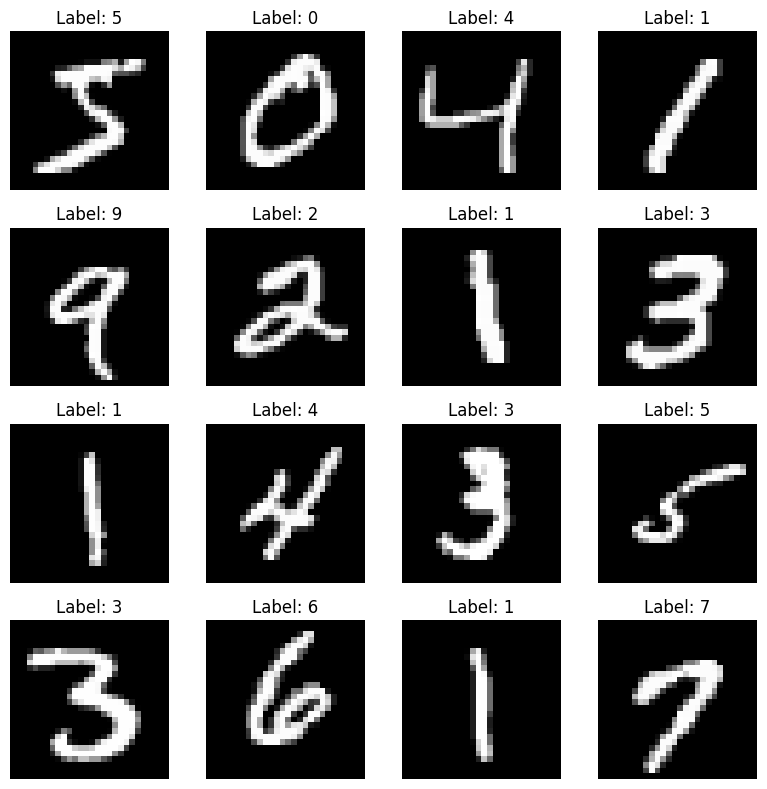

In [3]:
print("First 10 labels:", y_train_all[:10])

plt.figure(figsize=(8, 8))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(x_train_all[i], cmap="gray")
    plt.title(f"Label: {y_train_all[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 4. Normalize images and prepare the input shape

Pixel values originally range from 0 to 255. Dividing by 255 scales them to 0–1, which is a more suitable input range for neural network training. Add a final channel dimension because the CNN expects grayscale images with shape `(28, 28, 1)`.

This is done **before** splitting so training, validation, and test images all receive identical preprocessing.

In [4]:
x_train_all = x_train_all.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train_all = np.expand_dims(x_train_all, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Normalized training data:", x_train_all.shape)
print("Normalized test data:", x_test.shape)
print("Training pixel range:", x_train_all.min(), "to", x_train_all.max())
print("Test pixel range:", x_test.min(), "to", x_test.max())

Normalized training data: (60000, 28, 28, 1)
Normalized test data: (10000, 28, 28, 1)
Training pixel range: 0.0 to 1.0
Test pixel range: 0.0 to 1.0


## 5. Split training data into training and validation sets

Use 10% of the original training data for validation. Stratification preserves the approximate distribution of digit classes in both subsets. The official 10,000-image test set remains separate and is not used for model selection.

In [5]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train_all,
    y_train_all,
    test_size=0.1,
    random_state=42,
    stratify=y_train_all
)

print("Training set:", x_train.shape, y_train.shape)
print("Validation set:", x_val.shape, y_val.shape)
print("Test set:", x_test.shape, y_test.shape)

Training set: (54000, 28, 28, 1) (54000,)
Validation set: (6000, 28, 28, 1) (6000,)
Test set: (10000, 28, 28, 1) (10000,)


## 6. Build the CNN model

The model uses two convolutional blocks. Convolutional layers learn visual features such as edges and digit strokes; max-pooling reduces spatial dimensions. The dense layer combines learned features, and the final softmax layer outputs probabilities for the 10 digit classes.

In [6]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Train the model with early stopping

Early stopping monitors validation loss and stops training if it does not improve for three consecutive epochs. `restore_best_weights=True` restores the weights from the best validation-loss epoch. The callback must be passed to `model.fit()` for it to take effect.

In [7]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 58s 65ms/step - accuracy: 0.9485 - loss: 0.1674 - val_accuracy: 0.9792 - val_loss: 0.0716
Epoch 2/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 79s 61ms/step - accuracy: 0.9845 - loss: 0.0508 - val_accuracy: 0.9830 - val_loss: 0.0583
Epoch 3/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 62ms/step - accuracy: 0.9891 - loss: 0.0348 - val_accuracy: 0.9827 - val_loss: 0.0556
Epoch 4/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 50s 59ms/step - accuracy: 0.9919 - loss: 0.0264 - val_accuracy: 0.9887 - val_loss: 0.0387
Epoch 5/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 81s 59ms/step - accuracy: 0.9935 - loss: 0.0195 - val_accuracy: 0.9862 - val_loss: 0.0517
Epoch 6/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 83s 60ms/step - accuracy: 0.9946 - loss: 0.0158 - val_accuracy: 0.9875 - val_loss: 0.0459
Epoch 7/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 49s 58ms/step - accuracy: 0.9961 - loss: 0.0129 - val_accuracy: 0.9890 - val_loss: 0.0409


## 8. Plot training and validation performance

Accuracy and loss curves help compare learning on the training set with performance on the validation set. A widening gap can indicate overfitting.

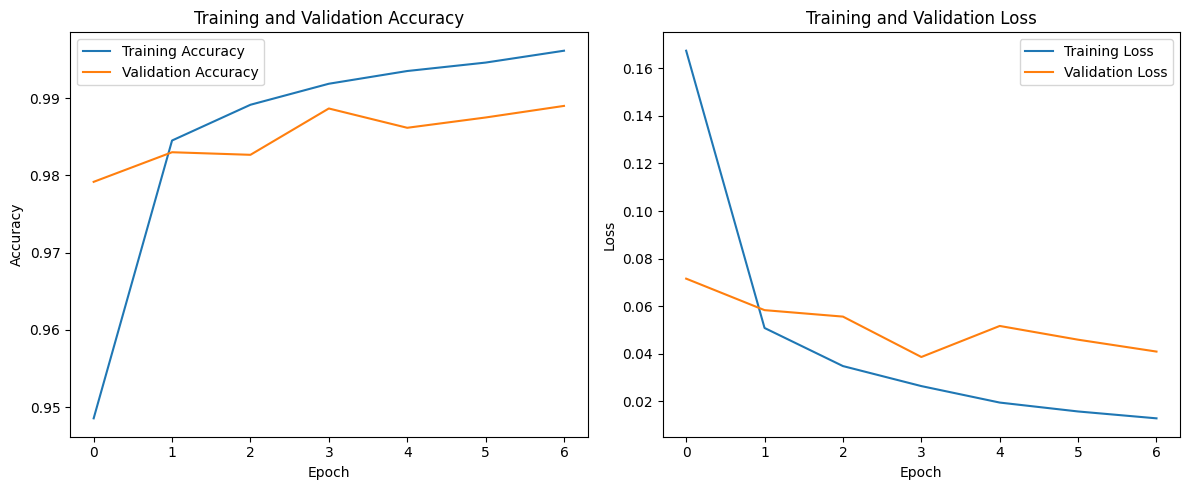

In [8]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 9. Evaluate on the test set

Evaluate the final model on the official test set only after training and validation are complete. These are the final generalization metrics for this run. Do not copy a previous accuracy value here; use the result produced by the corrected notebook.

In [9]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.0320
Test Accuracy: 98.94%


## 10. Classification report and confusion matrix

The classification report provides precision, recall, and F1-score for each digit class. The confusion matrix shows which digits the model most often confuses.

              precision    recall  f1-score   support

           0     0.9918    0.9929    0.9924       980
           1     0.9938    0.9894    0.9916      1135
           2     0.9884    0.9922    0.9903      1032
           3     0.9930    0.9881    0.9906      1010
           4     0.9889    0.9959    0.9924       982
           5     0.9844    0.9888    0.9866       892
           6     0.9947    0.9833    0.9890       958
           7     0.9826    0.9912    0.9869      1028
           8     0.9867    0.9877    0.9872       974
           9     0.9890    0.9841    0.9866      1009

    accuracy                         0.9894     10000
   macro avg     0.9893    0.9894    0.9893     10000
weighted avg     0.9894    0.9894    0.9894     10000



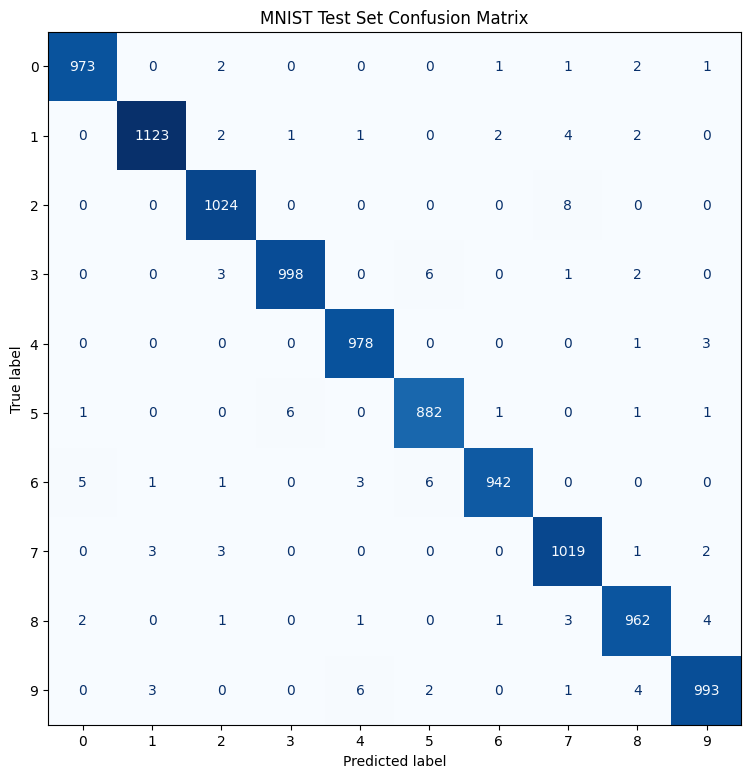

In [10]:
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(y_test, y_pred, digits=4))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)
fig, ax = plt.subplots(figsize=(9, 9))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("MNIST Test Set Confusion Matrix")
plt.show()

## 11. Inspect some incorrect predictions

This cell displays up to 12 test images that the model classified incorrectly. Error inspection can reveal which handwritten digits are visually difficult to distinguish.

Number of incorrect predictions: 106


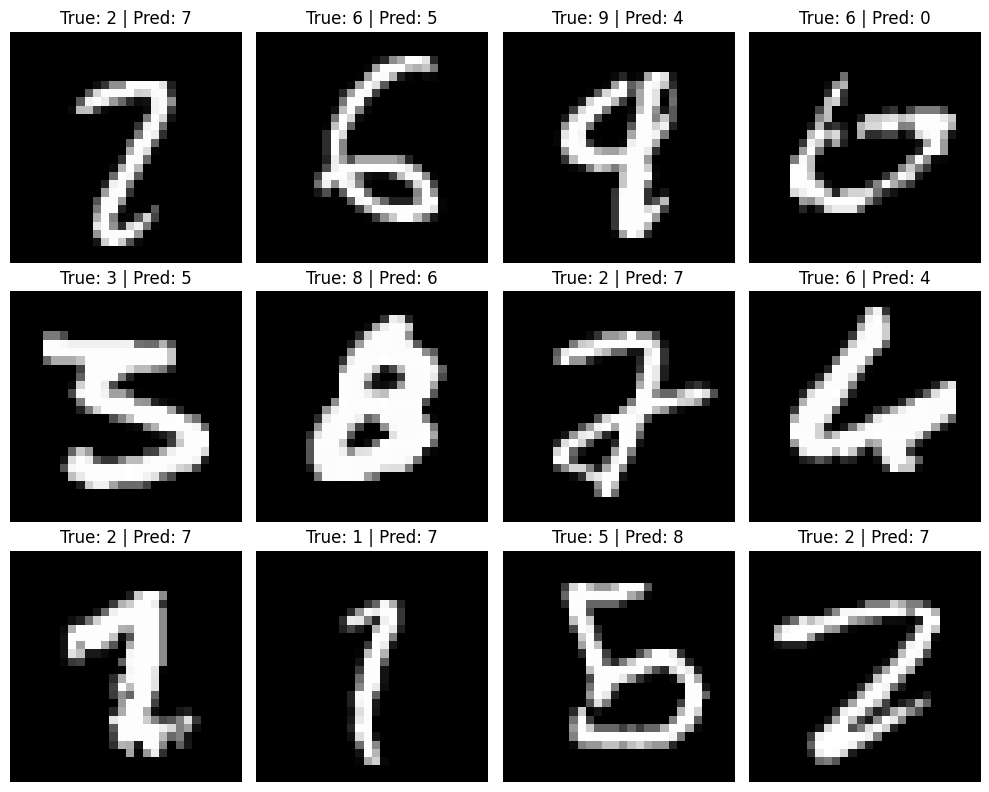

In [11]:
wrong_indices = np.where(y_pred != y_test)[0]
print("Number of incorrect predictions:", len(wrong_indices))

n_show = min(12, len(wrong_indices))
plt.figure(figsize=(10, 8))

for i, idx in enumerate(wrong_indices[:n_show]):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[idx].squeeze(), cmap="gray")
    plt.title(f"True: {y_test[idx]} | Pred: {y_pred[idx]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 12. Optional: Predict a custom image

This optional section predicts a user-provided image. Upload a file to the Colab session or update `image_path`. The input should contain one clearly visible digit. The preprocessing below converts it to grayscale, resizes it to 28 × 28, scales pixel values, and inverts it to the white-digit-on-black-background style used by MNIST.

**Note:** A custom image may need centering, cropping, and background cleanup to resemble MNIST. A prediction confidence score is not proof that the prediction is correct.

In [13]:
import os
from PIL import Image, ImageOps

# Update this path to the location of your own digit image.
image_path = "/content/your_digit_image.png"

if not os.path.exists(image_path):
    print(f"Error: The file '{image_path}' was not found.")
    print("Please upload your custom digit image to the Colab files section (left sidebar) and update 'image_path' with the correct filename.")
else:
    custom_image = Image.open(image_path).convert("L")
    custom_image = ImageOps.invert(custom_image)
    custom_image = custom_image.resize((28, 28))

    custom_array = np.asarray(custom_image, dtype="float32") / 255.0
    custom_array = custom_array.reshape(1, 28, 28, 1)

    plt.imshow(custom_array[0].squeeze(), cmap="gray")
    plt.title("Preprocessed Custom Digit")
    plt.axis("off")
    plt.show()

    custom_probabilities = model.predict(custom_array, verbose=0)
    custom_digit = int(np.argmax(custom_probabilities[0]))
    custom_confidence = float(np.max(custom_probabilities[0]))

    print("Predicted digit:", custom_digit)
    print(f"Prediction confidence: {custom_confidence * 100:.2f}%")

Error: The file '/content/your_digit_image.png' was not found.
Please upload your custom digit image to the Colab files section (left sidebar) and update 'image_path' with the correct filename.


## 13. Save the trained model

Save the trained Keras model so it can be loaded later without training again.

In [14]:
model.save("mnist_cnn_model.keras")
print("Model saved as mnist_cnn_model.keras")

Model saved as mnist_cnn_model.keras


## Conclusion

This notebook demonstrates an end-to-end CNN workflow for handwritten digit classification using MNIST. The corrected workflow uses consistent normalization, a separate validation split, early stopping, and a final evaluation on the untouched test set.

Record the final test accuracy and loss from Section 9 after running all cells from a fresh runtime. Results from the earlier notebook run are not carried forward because its training/validation and test preprocessing were inconsistent.